# Breast Cancer Coimbra Dataset Analysis

**A Feature Selection and Support Vector Machine-Based Framework for Breast Cancer Classification**

This is a separate analysis of the UCI Breast Cancer Coimbra dataset. It will not be combined with the Wisconsin Diagnostic dataset. Coimbra predicts patient status (breast cancer patient vs healthy control), while Wisconsin predicts benign vs malignant diagnosis, so their results are not directly interchangeable.

The UCI dataset contains 116 observations and 9 quantitative predictors. Its `Classification` target uses 1 for healthy controls and 2 for patients. [UCI dataset page](https://archive.ics.uci.edu/dataset/451/breast%2Bcancer%2Bcoimbra%29.)


## 1. Hosted Environment and Imports

Run the setup/import cell first in Google Colab. The package install is included because Colab may not have `ucimlrepo` already installed.


In [1]:
%pip install -q ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo


## 2. Load the Coimbra Dataset

Fetch UCI dataset 451. Keep the predictors (`X`) and target (`y`) as separate variables for this dataset.


In [2]:
coimbra_dataset = fetch_ucirepo(id=451)
X = coimbra_dataset.data.features.copy()
y = coimbra_dataset.data.targets.squeeze().copy()

print("Dataset shape (observations, predictors):", X.shape)
print("Target name:", y.name)
print("Target label counts:")
print(y.value_counts().sort_index())

display(X.head())
display(y.head())


Dataset shape (observations, predictors): (116, 9)
Target name: Classification
Target label counts:
Classification
1    52
2    64
Name: count, dtype: int64


,Age,BMI,Glucose,Insulin,HOMA,Leptin,Adiponectin,Resistin,MCP.1
0,48,23.500000,70,2.707,0.467409,8.8071,9.702400,7.99585,417.114
1,83,20.690495,92,3.115,0.706897,8.8438,5.429285,4.06405,468.786
2,82,23.124670,91,4.498,1.009651,17.9393,22.432040,9.27715,554.697
3,68,21.367521,77,3.226,0.612725,9.8827,7.169560,12.76600,928.220
4,86,21.111111,92,3.549,0.805386,6.6994,4.819240,10.57635,773.920


,Classification
0,1
1,1
2,1
3,1
4,1


## 3. Understand the Dataset

Check data types, missing values, class balance, and descriptive statistics before preprocessing.


In [3]:
print("Feature data types:")
print(X.dtypes.value_counts())
print("Missing predictor values:", X.isna().sum().sum())
print("Duplicate predictor rows:", X.duplicated().sum())
print("Feature summary:")
display(X.describe().T)


Feature data types:
float64    7
int64      2
Name: count, dtype: int64
Missing predictor values: 0
Duplicate predictor rows: 0
Feature summary:


,count,mean,std,min,25%,50%,75%,max
Age,116.0,57.301724,16.112766,24.000000,45.000000,56.000000,71.000000,89.000000
BMI,116.0,27.582111,5.020136,18.370000,22.973205,27.662416,31.241442,38.578759
Glucose,116.0,97.793103,22.525162,60.000000,85.750000,92.000000,102.000000,201.000000
Insulin,116.0,10.012086,10.067768,2.432000,4.359250,5.924500,11.189250,58.460000
HOMA,116.0,2.694988,3.642043,0.467409,0.917966,1.380939,2.857787,25.050342
Leptin,116.0,26.615080,19.183294,4.311000,12.313675,20.271000,37.378300,90.280000
Adiponectin,116.0,10.180874,6.843341,1.656020,5.474283,8.352692,11.815970,38.040000
Resistin,116.0,14.725966,12.390646,3.210000,6.881763,10.827740,17.755207,82.100000
MCP.1,116.0,534.647000,345.912663,45.843000,269.978250,471.322500,700.085000,1698.440000


## 4. Preprocess the Target

The UCI coding is 1 = healthy control and 2 = breast cancer patient. Encode controls as 0 and patients as 1 so malignant/patient recall and false negatives can be calculated consistently.


In [4]:
y_numeric = pd.to_numeric(y, errors="raise").astype("int64")
observed_labels = set(y_numeric.unique())
print("Observed target labels:", sorted(observed_labels))

if observed_labels != {1, 2}:
    raise ValueError("Expected Coimbra labels 1 (healthy) and 2 (patient). Check the UCI target values.")

y_encoded = y_numeric.map({1: 0, 2: 1}).astype("int64")
print("Encoded class counts (0=healthy, 1=patient):")
print(y_encoded.value_counts().sort_index())


Observed target labels: [np.int64(1), np.int64(2)]
Encoded class counts (0=healthy, 1=patient):
Classification
0    52
1    64
Name: count, dtype: int64


## 5. Exploratory Data Analysis

Explore class balance and the distributions of the clinical predictors. Interpret patterns cautiously because this dataset is small.


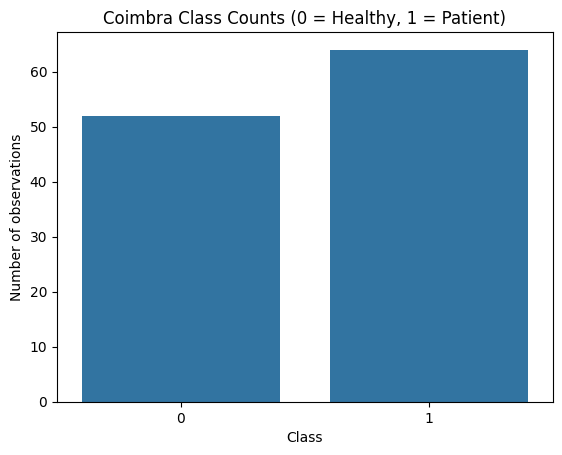

In [5]:
sns.countplot(x=y_encoded)
plt.title("Coimbra Class Counts (0 = Healthy, 1 = Patient)")
plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.show()


## 6. Feature Selection

Compare no feature selection, SelectKBest, and Recursive Feature Elimination (RFE). Keep feature selection inside the training pipeline to avoid leaking test data.


## 7. Support Vector Machine

Compare linear and RBF SVM kernels. The outcome here is patient vs healthy control; it is different from benign vs malignant classification in the Wisconsin study.


## 8. Model Training

Use a stratified train/test split and stratified cross-validation on the training data. Because this dataset has only 116 observations, report the split and its limitations clearly.


## 9. Model Evaluation

Report accuracy, patient-class precision and recall, F1-score, and the confusion matrix. Interpret patient recall and false negatives carefully.


## 10. False Negative Analysis

A false negative is a patient case predicted as a healthy control. Inspect these cases and discuss why this error matters.


## 11. Results and Discussion

Summarize the cross-validation comparison and held-out test results for this dataset only.


## 12. Conclusion

State what the Coimbra experiment found, its limitations, and how it differs from the Wisconsin Diagnostic experiment. Do not combine metrics across the two datasets.
